# Logistic Regression

In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
df1=pd.read_csv("C://Users//ANJALI//Downloads//diabetes.csv")
df1.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
df1.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
df1.shape

(768, 9)

In [9]:
df1.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

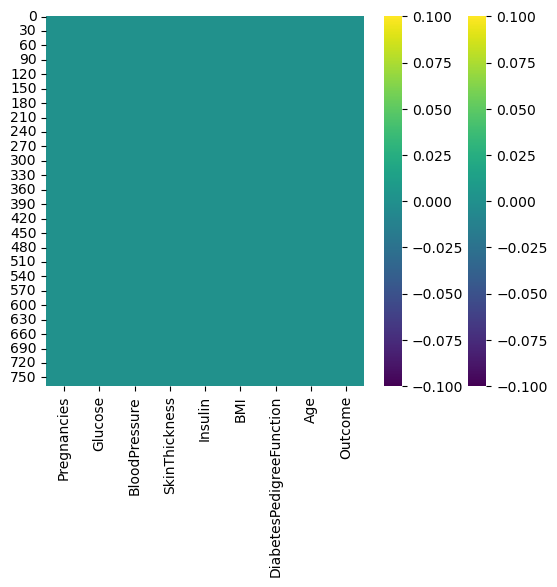

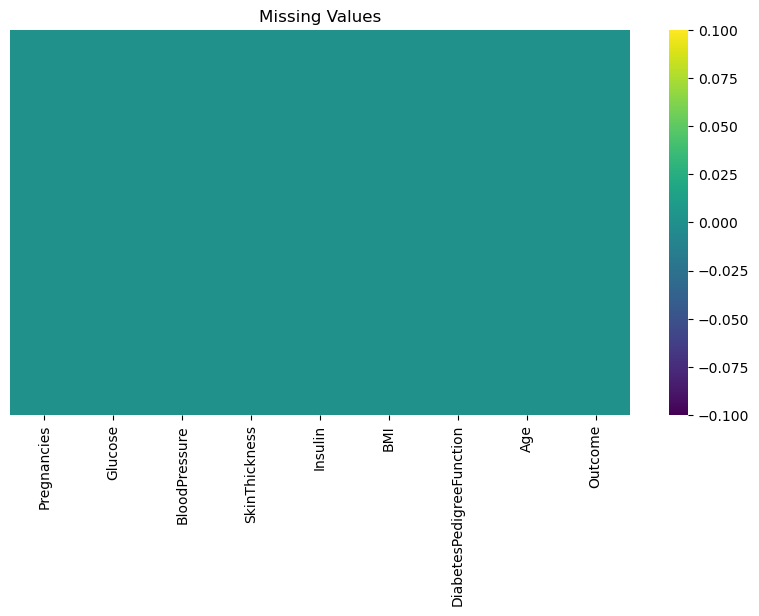

In [10]:
plt.figure(figsize=(10, 5))

sns.heatmap(df1.isnull(), yticklabels=False, cmap='viridis')

plt.title("Missing Values")
plt.show()

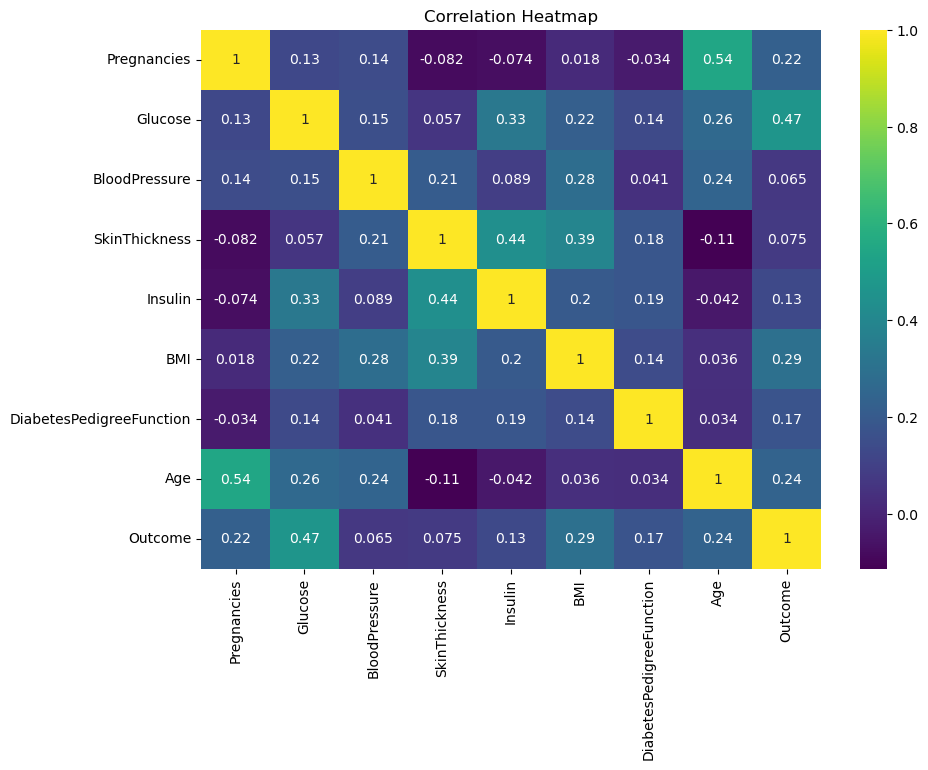

In [12]:
plt.figure(figsize=(10, 7))

sns.heatmap(df1.corr(), annot=True, cmap='viridis')

plt.title("Correlation Heatmap")
plt.show()

# Count of diabetic and non-diabetic patients

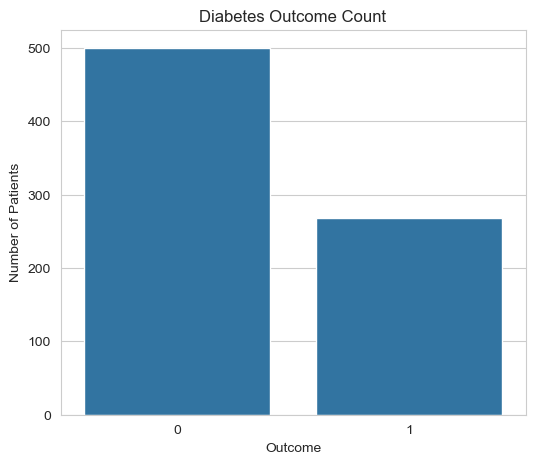

In [13]:
sns.set_style("whitegrid")

plt.figure(figsize=(6, 5))

sns.countplot(x='Outcome', data=df1)

plt.title("Diabetes Outcome Count")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.show()

# Bar plot of Age and Blood Pressure

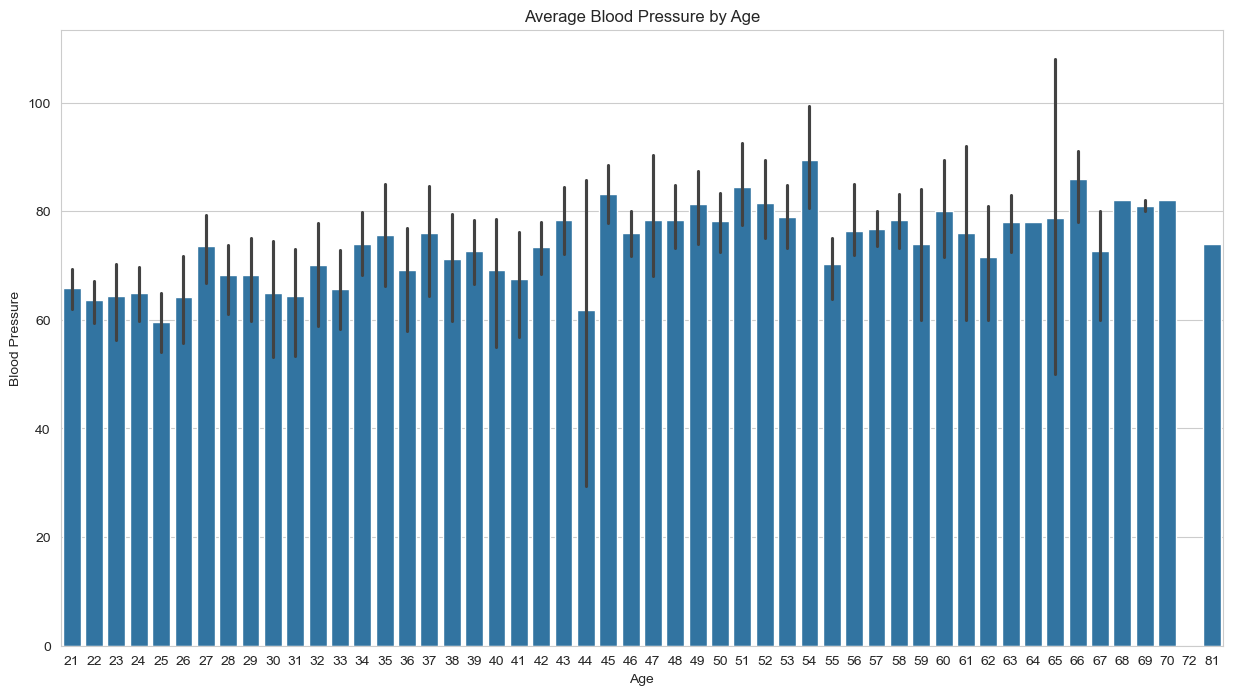

In [14]:
plt.figure(figsize=(15, 8))

sns.barplot(
    x='Age',
    y='BloodPressure',
    data=df1
)

plt.title("Average Blood Pressure by Age")
plt.xlabel("Age")
plt.ylabel("Blood Pressure")

plt.show()

In [15]:
y=['Output']

In [17]:
X = df1[
    [
        'Pregnancies',
        'Glucose',
        'BloodPressure',
        'SkinThickness',
        'Insulin',
        'BMI',
        'DiabetesPedigreeFunction',
        'Age'
    ]
]

y = df1['Outcome']

print(X.head())
print(y.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  
0                     0.627   50  
1                     0.351   31  
2                     0.672   32  
3                     0.167   21  
4                     2.288   33  
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


# Split dataset into training and testing data

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=101,
    stratify=y
)

# Check training and testing data

In [19]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [20]:
from sklearn.linear_model import LogisticRegression

LRModel = LogisticRegression(
    solver='lbfgs',
    max_iter=7600
)
LRModel.fit(X_train, y_train)

LogisticRegression(max_iter=7600)

In [21]:
predictions_diabetes = LRModel.predict(X_test)

print(predictions_diabetes)

[0 0 0 1 1 0 0 0 0 1 1 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 1 1 1 1
 0 1 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 0 1 0 1 1 0 0 1 0 0 0 0 0 1 0 0 0 0 1
 1 0 0 0 0 0 1 1 0 1 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0
 0 1 0 0 0 0]


In [22]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predictions_diabetes))

              precision    recall  f1-score   support

           0       0.77      0.90      0.83       100
           1       0.73      0.50      0.59        54

    accuracy                           0.76       154
   macro avg       0.75      0.70      0.71       154
weighted avg       0.76      0.76      0.75       154



# Confusion Matrix

In [23]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, predictions_diabetes)

print(cm)

[[90 10]
 [27 27]]


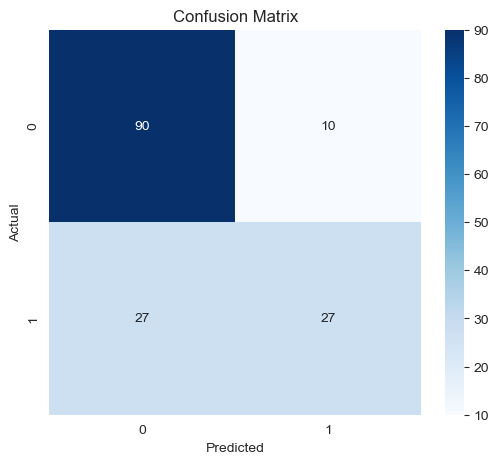

In [24]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [26]:
features = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
]
data = [
    0,
    170,
    126,
    60,
    35,
    30.1,
    0.649,
    78
]

patient_data = pd.DataFrame(
    [data],
    columns=features
)

patient_data



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0,170,126,60,35,30.1,0.649,78


In [28]:
prediction = LRModel.predict(patient_data)

print("Prediction:", prediction)

# If output is:

# Prediction: [1]

# then:

# Patient is predicted to have diabetes.

# If output is:

# Prediction: [0]

# then:

# Patient is predicted not to have diabetes.

Prediction: [1]


In [29]:
prediction = LRModel.predict(patient_data)

if prediction[0] == 1:
    print("The model predicts that the patient may have diabetes.")
else:
    print("The model predicts that the patient may not have diabetes.")

The model predicts that the patient may have diabetes.
